# Independent Project 2: Frequent Patterns, Sequences & Data Streams
**100 points · 10 questions × 10**

Per question: **experiment executed & numbers reported (5)** · **explanation (5)**.
All formulas you need are printed in the handout. Every `TODO` is yours; every `assert` is a self-check — if an assert defeats you, add that question to `FALLBACK` so later cells still run.

In [1]:
%pip install -q scanpy leidenalg igraph scikit-learn scipy matplotlib mlxtend

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# ---- Setup (run once) ----
# Version pins are for Google Colab only. Locally: pip install scanpy leidenalg igraph scikit-learn scipy matplotlib mlxtend
import sys, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    os.system("pip uninstall -y numpy scipy >/dev/null 2>&1")
    for p in ["numpy", "numpy.libs", "numpy-*.dist-info", "scipy", "scipy.libs", "scipy-*.dist-info"]:
        os.system(f"rm -rf /usr/local/lib/python3.12/dist-packages/{p}")
    os.system('pip install -q --no-cache-dir "numpy==2.2.6" "scipy==1.15.3" "scanpy==1.11.4" "igraph==0.11.8" "leidenalg==0.10.2" "mlxtend>=0.23"')
    print("Colab: pinned versions installed - now RESTART the runtime (Runtime > Restart session) and run from the next cell.")
else:
    print("Local environment detected - using your installed versions (no pins applied).")

Local environment detected - using your installed versions (no pins applied).


In [4]:
import numpy as np, pandas as pd, hashlib, math, itertools, collections
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.sparse.linalg import svds

np.random.seed(0); sc.settings.verbosity = 1
FALLBACK = set()          # e.g. FALLBACK.add("Q4") if an assert defeats you

# ---- Project-1 pipeline, replayed (given) ----
adata = sc.datasets.pbmc3k(); adata.var_names_make_unique()
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
sc.pp.normalize_total(adata, target_sum=1e4); sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
adata_hvg = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=50, svd_solver="arpack")
sc.pp.neighbors(adata_hvg, n_neighbors=15, n_pcs=50)
sc.tl.leiden(adata_hvg, resolution=1.0, key_added="leiden", flavor="igraph", n_iterations=2, directed=False, random_state=0)
Z = adata_hvg.obsm["X_pca"]
leiden = adata_hvg.obs["leiden"].values.astype(str)
print(adata.shape, "| Leiden clusters:", pd.Series(leiden).value_counts().to_dict())

# ---- Transactions: cells of the LARGEST cluster; items: HVGs detected in 20–60% of those cells (given) ----
DET = (adata[:, adata_hvg.var_names].layers["counts"] > 0)          # cell x HVG detection (sparse bool)
DET = DET.toarray() if hasattr(DET, "toarray") else np.asarray(DET)
cl_big = pd.Series(leiden).value_counts().index[0]
cells_big = np.where(leiden == cl_big)[0]
det_rate = DET[cells_big].mean(0)
band = np.where((det_rate >= 0.2) & (det_rate <= 0.6))[0]
band = band[np.argsort(-DET[cells_big][:, band].var(0))][:60]        # 60 most variable genes in the band
B = DET[cells_big][:, band].astype(np.uint8)                          # transactions x items (0/1)
ITEMS = np.array(adata_hvg.var_names)[band]
print("transaction matrix B:", B.shape, "| cluster", cl_big, "| detection-rate range:", det_rate[band].min().round(2), det_rate[band].max().round(2))

c:\Users\wages\AppData\Local\Programs\Python\Python311\Lib\site-packages\scanpy\_utils\__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
c:\Users\wages\AppData\Local\Programs\Python\Python311\Lib\site-packages\scanpy\__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
c:\Users\wages\AppData\Local\Programs\Python\Python311\Lib\site-packages\scanpy\readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
c:\Users\wages\AppData\Local\Programs\Python\Python311\Lib\site-packages\scanpy\datasets\_utils.py:35: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(ad.__version__).release >= (0

(2700, 32738) | Leiden clusters: {'0': 768, '2': 492, '4': 440, '5': 430, '1': 347, '3': 157, '6': 36, '7': 16, '8': 14}
transaction matrix B: (768, 60) | cluster 0 | detection-rate range: 0.3 0.59


---
## Question 1 (10 pts):

In [5]:
from mlxtend.frequent_patterns import apriori as mlx_apriori

def support(B, itemset):
    """itemset: tuple of column indices. Return fraction of rows where ALL those columns are 1."""
    # TODO(1): no python loop over rows (hint: B[:, list(itemset)].all(1).mean())
    return B[:, list(itemset)].all(1).mean()
    raise NotImplementedError

def my_apriori(B, minsup, max_len=3):
    """Level-wise Apriori. Return (freq, n_candidates) where
    freq = {itemset(tuple, sorted): support} for all frequent itemsets with len <= max_len,
    n_candidates = {k: number of k-itemsets whose support you actually COUNTED}."""
    n_items = B.shape[1]
    freq, n_cand = {}, {}
    # TODO(2): level 1 - count every single item
    for i in range(n_items):
        s = support(B, (i,))
        n_cand[1] = n_cand.get(1, 0) + 1
        if s >= minsup:
            freq[(i,)] = s
    # TODO(3): level k>=2 - generate candidates by joining frequent (k-1)-itemsets that share a (k-2)-prefix,
    #          PRUNE any candidate having an infrequent (k-1)-subset (downward closure), then count the survivors
    for k in range(2, max_len + 1):
        # Generate candidates by joining frequent (k-1)-itemsets
        prev_freq_itemsets = [itemset for itemset in freq if len(itemset) == k - 1]
        candidates = set()
        for i in range(len(prev_freq_itemsets)):
            for j in range(i + 1, len(prev_freq_itemsets)):
                # Join if they share a (k-2)-prefix
                if prev_freq_itemsets[i][:-1] == prev_freq_itemsets[j][:-1]:
                    candidate = tuple(sorted(set(prev_freq_itemsets[i]) | set(prev_freq_itemsets[j])))
                    if len(candidate) == k:
                        # Prune if any (k-1)-subset is infrequent
                        if all(tuple(sorted(subset)) in freq for subset in itertools.combinations(candidate, k - 1)):
                            candidates.add(candidate)
        
        # Count support for candidates
        n_cand[k] = len(candidates)
        for candidate in candidates:
            s = support(B, candidate)
            if s >= minsup:
                freq[candidate] = s
    return freq, n_cand
    raise NotImplementedError

# ---- assert vs mlxtend on the same B / minsup ----
freq, ncand = my_apriori(B, 0.30, 3)
ref = mlx_apriori(pd.DataFrame(B.astype(bool)), min_support=0.30, use_colnames=False, max_len=3)
ref_d = {tuple(sorted(s)): v for s, v in zip(ref["itemsets"], ref["support"])}
assert set(freq) == set(ref_d), "Q1 assert FAILED - different set of frequent itemsets"
assert all(abs(freq[s] - ref_d[s]) < 1e-9 for s in freq), "Q1 assert FAILED - support values differ"
print("Q1 assert PASSED |", len(freq), "frequent itemsets at minsup=0.30 | candidates counted per level:", ncand)

Q1 assert PASSED | 114 frequent itemsets at minsup=0.30 | candidates counted per level: {1: 60, 2: 1711, 3: 98}


In [6]:
# ---- EXPERIMENT (given): the price of counting, with and without downward closure ----
from math import comb
ap_fn = my_apriori if "Q1" not in FALLBACK else (lambda B, s, L: ({tuple(sorted(i)): v for i, v in zip(*[mlx_apriori(pd.DataFrame(B.astype(bool)), min_support=s, max_len=L)[c] for c in ["itemsets", "support"]])}, {}))
rows = []
for s in [0.25, 0.30, 0.35]:
    f, nc = ap_fn(B, s, 3)
    by_len = collections.Counter(len(k) for k in f)
    rows.append({"minsup": s, "L1": by_len.get(1, 0), "L2": by_len.get(2, 0), "L3": by_len.get(3, 0),
                 "candidates counted": nc, "brute force": {1: B.shape[1], 2: comb(B.shape[1], 2), 3: comb(B.shape[1], 3)}})
print(pd.DataFrame(rows).to_string(index=False))
# the three most frequent pairs, by name
f30, _ = ap_fn(B, 0.30, 3)
top_pairs = sorted([(v, k) for k, v in f30.items() if len(k) == 2], reverse=True)[:3]
print("top pairs:", [(ITEMS[list(k)].tolist(), round(v, 3)) for v, k in top_pairs])

 minsup  L1  L2  L3       candidates counted                brute force
   0.25  60 161   0 {1: 60, 2: 1770, 3: 604} {1: 60, 2: 1770, 3: 34220}
   0.30  59  55   0  {1: 60, 2: 1711, 3: 98} {1: 60, 2: 1770, 3: 34220}
   0.35  38   3   0    {1: 60, 2: 703, 3: 1} {1: 60, 2: 1770, 3: 34220}
top pairs: [(['ATP6V0E1', 'CAPZB'], np.float64(0.37)), (['ARL6IP5', 'ATP6V0E1'], np.float64(0.359)), (['ARL6IP5', 'CAPZB'], np.float64(0.357))]


**1.	Report, for each minsup, how many candidate itemsets you counted at levels 2 and 3 versus the brute-force number of 2- and 3-itemsets over 60 items. Which property of support makes this reduction legitimate rather than approximate? State the property and explain why it only tells you what *cannot* be frequent.**

minsup
0.25
0.30
0.35

**2.	Compare the number of frequent itemsets across the three minsup values. Is the number of frequent 2-itemsets a property of the data, of the threshold, or of both? Pick one of your top pairs and say what it would take (beyond support) to call it a biological finding.**

---
## Question 2 (10 pts):

In [ ]:
def closed_itemsets(freq):
    """freq: {itemset(tuple): support}. Return the subset of itemsets that are CLOSED
    (no proper superset in freq has the same support)."""
    # TODO(1)
    closed = set()
    for itemset in freq:
        is_closed = True
        for superset in freq:
            if itemset != superset and set(itemset).issubset(set(superset)):
                if freq[itemset] == freq[superset]:
                    is_closed = False
                    break
        if is_closed:
            closed.add(itemset)
    return closed

def maximal_itemsets(freq): NOT DONE
    """Return the subset of itemsets with NO frequent proper superset in freq."""
    # TODO(2)
    maximal = set()
    for itemset in freq:
        is_maximal = True
        for superset in freq:
            if itemset != superset and set(itemset).issubset(set(superset)):
                if freq[itemset] == freq[superset]:
                    is_maximal = False
                    break
        if is_maximal:
            maximal.add(itemset)
    print(maximal)
    return maximal

def recover_support(itemset, closed):
    """Support of ANY frequent itemset = support of its CLOSURE = the LARGEST support among its closed supersets (max over closed supersets)."""
    # TODO(3)
    for closed_itemset in closed:
        if set(itemset).issubset(set(closed_itemset)):
            return closed[closed_itemset]
        else:
            return 0.0
    raise NotImplementedError

def tidset_support(B, itemset):
    """Vertical representation: intersect the row-index sets (tidsets) of the items, return fraction of rows."""
    # TODO(4): build tidsets with np.flatnonzero, intersect with set.intersection or np.intersect1d
    tids = [set(np.flatnonzero(B[:, i])) for i in itemset]
    if not tids:
        return 0.0
    intersection = set.intersection(*tids)
    return len(intersection) / B.shape[0]
    raise NotImplementedError

# ---- asserts: (a) the handout's DB-2 toy (compression visible), (b) lossless recovery + vertical == horizontal on real data ----
toy = {(0,): 0.8, (1,): 0.8, (2,): 0.8, (0, 1): 0.6, (0, 2): 0.6, (1, 2): 0.8, (0, 1, 2): 0.6}     # A,B,C,AB,AC,BC,ABC of DB-2
assert set(closed_itemsets(toy)) == {(0,), (1, 2), (0, 1, 2)}, "Q2 assert FAILED - DB-2 closed set should be {A, BC, ABC}"
assert set(maximal_itemsets(toy)) == {(0, 1, 2)}, "Q2 assert FAILED - DB-2 maximal set should be {ABC}"
assert abs(recover_support((1,), closed_itemsets(toy)) - 0.8) < 1e-9 and abs(recover_support((0, 1), closed_itemsets(toy)) - 0.6) < 1e-9, "Q2 assert FAILED - recovery on DB-2"
freq30 = ap_fn(B, 0.30, 3)[0]
C30, M30 = closed_itemsets(freq30), maximal_itemsets(freq30)
assert all(abs(recover_support(s, C30) - freq30[s]) < 1e-9 for s in freq30), "Q2 assert FAILED - closed set is not lossless"
assert set(M30) <= set(C30) <= set(freq30), "Q2 assert FAILED - maximal ⊆ closed ⊆ frequent violated"
assert all(abs(tidset_support(B, s) - freq30[s]) < 1e-9 for s in freq30 if len(s) == 2), "Q2 assert FAILED - tidset support ≠ Apriori support"
print("Q2 asserts PASSED | frequent:", len(freq30), "closed:", len(C30), "maximal:", len(M30))

{(0,), (1, 2), (0, 1, 2)}


AssertionError: Q2 assert FAILED - DB-2 maximal set should be {ABC}

In [9]:
# ---- EXPERIMENT (given): three summaries of one truth ----
def closed_within(f, tol):
    """approximately closed: no proper superset whose support is within `tol` of mine"""
    return [x for x in f if not any(set(x) < set(t) and f[x] - f[t] <= tol + 1e-12 for t in f)]
n_cells_B = B.shape[0]; rows = []
for s in [0.25, 0.30, 0.35]:
    f = ap_fn(B, s, 3)[0]; C, M = closed_itemsets(f), maximal_itemsets(f)
    rows.append({"minsup": s, "frequent": len(f), "closed (exact)": len(C),
                 "closed (δ=1% cells)": len(closed_within(f, 0.01)), "closed (δ=5% cells)": len(closed_within(f, 0.05)),
                 "maximal": len(M), "maximal/frequent": round(len(M) / len(f), 3)})
print(pd.DataFrame(rows).to_string(index=False))
print(f"(δ=1% ≈ {0.01*n_cells_B:.0f} cells, δ=5% ≈ {0.05*n_cells_B:.0f} cells of {n_cells_B})")
# a non-closed example and what it tells you
f = ap_fn(B, 0.30, 3)[0]; C = closed_itemsets(f)
nonclosed = [s for s in f if s not in C and len(s) == 1]
if nonclosed:
    g = nonclosed[0]; sup = [t for t in C if set(g) < set(t) and abs(f[t] - f[g]) < 1e-9][0]
    print(f"{ITEMS[g[0]]} is NOT closed: supp={f[g]:.3f} equals supp of {ITEMS[list(sup)].tolist()} -> every cell expressing {ITEMS[g[0]]} also expresses the rest")
else:
    near = [(g, t) for g in f if len(g) == 1 for t in f if set(g) < set(t) and f[g] - f[t] <= 1.0 / B.shape[0] + 1e-12]
    print("no EXACTLY non-closed singleton at minsup=0.30;", len(near), "singletons are closed only by a margin of one cell, e.g.",
          [(ITEMS[g[0]], ITEMS[list(t)].tolist(), round(f[g] - f[t], 4)) for g, t in near[:3]])

{(6, 18), (16, 20), (3, 13), (5, 10), (8, 9), (20,), (0, 5), (3, 22), (8, 18), (29,), (14, 22), (38,), (47,), (1, 15), (56,), (1, 24), (24, 26), (6, 20), (16, 22), (18, 19), (3, 6), (20, 22), (13,), (12, 18), (3, 15), (14, 15), (8, 11), (22,), (5, 12), (14, 24), (2, 4), (3, 24), (31,), (9, 10), (40,), (1, 8), (49,), (10, 20), (15, 16), (6, 13), (16, 24), (6,), (3, 8), (20, 24), (15,), (12, 20), (24,), (33,), (42,), (1, 10), (10, 22), (15, 18), (24, 30), (8,), (12, 13), (3, 10), (5, 7), (22, 23), (17,), (12, 22), (0, 2), (4, 18), (26,), (35,), (1, 3), (44,), (10, 15), (10, 24), (13, 23), (2, 20), (1,), (10,), (12, 15), (19,), (12, 24), (23, 24), (5, 18), (4, 20), (28,), (37,), (1, 5), (8, 20), (13, 16), (2, 13), (2, 22), (58,), (3,), (3, 5), (20, 21), (6, 22), (12,), (4, 13), (21,), (22, 27), (4, 22), (30,), (1, 22), (8, 13), (2, 6), (8, 22), (13, 18), (0, 18), (11, 18), (2, 15), (2, 24), (51,), (6, 15), (5,), (6, 24), (4, 6), (14,), (21, 22), (3, 16), (5, 13), (4, 15), (23,), (4, 24), 

**1.	Report frequent / exactly-closed / maximal counts at the three thresholds. On the DB-2 toy the closed set compresses 7 → 3 losslessly; on the real matrix, how much does exact closure compress, and why? Use `recover_support` to explain how a support is reconstructed from the closed set, and what exactly the maximal set loses.**



**2.	Compare the exact closed count with the δ = 1% and δ = 5% counts. Why is exact closure essentially absent in single-cell detection data even when two genes are biologically co-regulated (think dropout)? Interpret supp(G) ≈ supp(G ∪ H) biologically, and state precisely what the lossless guarantee becomes once a tolerance δ is allowed.**

---
## Question 3 (10 pts):

In [10]:
from mlxtend.frequent_patterns import association_rules as mlx_rules

def my_rules(freq, min_conf=0.0):
    """From frequent itemsets of size >= 2, produce every rule X -> Y with X,Y nonempty, X ∪ Y = itemset, X ∩ Y = ∅.
    Return a DataFrame with columns: antecedent, consequent, support, confidence, lift, leverage."""
    # TODO(1): confidence = supp(X∪Y)/supp(X); lift = confidence/supp(Y); leverage = supp(X∪Y) - supp(X)*supp(Y)
    rules = []
    for itemset in freq:
        if len(itemset) >= 2:
            itemset_support = freq[itemset]
            for i in range(1, len(itemset)):
                for antecedent in itertools.combinations(itemset, i):
                    consequent = tuple(sorted(set(itemset) - set(antecedent)))
                    antecedent_support = freq[antecedent]
                    consequent_support = freq[consequent]
                    confidence = itemset_support / antecedent_support
                    lift = confidence / consequent_support
                    leverage = itemset_support - (antecedent_support * consequent_support)
                    rules.append({
                        'antecedent': frozenset(antecedent),
                        'consequent': frozenset(consequent),
                        'support': itemset_support,
                        'confidence': confidence,
                        'lift': lift,
                        'leverage': leverage
                    })
    return pd.DataFrame(rules)
    raise NotImplementedError

# ---- assert vs mlxtend on the same frequent itemsets ----
f30 = ap_fn(B, 0.30, 3)[0]
mine = my_rules(f30, 0.0)
ref_fi = pd.DataFrame({"support": list(f30.values()), "itemsets": [frozenset(k) for k in f30]})
ref = mlx_rules(ref_fi, metric="confidence", min_threshold=0.0)
key = lambda a, c: (tuple(sorted(a)), tuple(sorted(c)))
ref_d = {key(a, c): (conf, lift) for a, c, conf, lift in zip(ref["antecedents"], ref["consequents"], ref["confidence"], ref["lift"])}
assert len(mine) == len(ref_d), f"Q3 assert FAILED - {len(mine)} rules vs mlxtend {len(ref_d)}"
assert all(abs(r.confidence - ref_d[key(r.antecedent, r.consequent)][0]) < 1e-9 and abs(r.lift - ref_d[key(r.antecedent, r.consequent)][1]) < 1e-9 for r in mine.itertuples()), "Q3 assert FAILED - confidence/lift mismatch"
print("Q3 assert PASSED |", len(mine), "rules")

Q3 assert PASSED | 110 rules


In [11]:
# ---- EXPERIMENT (given): the confidence trap, then Simpson across two cell populations ----
R = mine.copy()
R["antecedent"] = R["antecedent"].apply(lambda t: ITEMS[list(t)].tolist()); R["consequent"] = R["consequent"].apply(lambda t: ITEMS[list(t)].tolist())
top_conf = R.sort_values("confidence", ascending=False).head(10)
top_lift = R.sort_values("lift", ascending=False).head(10)
overlap = len(set(map(str, top_conf[["antecedent", "consequent"]].values.tolist())) & set(map(str, top_lift[["antecedent", "consequent"]].values.tolist())))
print("top-10 by confidence ∩ top-10 by lift:", overlap, "rules")
neg = R[R.lift < 1.0].sort_values("confidence", ascending=False)
neg = neg.assign(baseline_supp_consequent=[f30[tuple(sorted(np.where(np.isin(ITEMS, c))[0]))] for c in neg["consequent"]])
print(f"rules with lift < 1 (negative association): {len(neg)} of {len(R)}; the five with the HIGHEST confidence among them:")
print(neg.head(5)[["antecedent", "consequent", "confidence", "baseline_supp_consequent", "lift"]].to_string(index=False))

# Simpson: pool the two largest clusters, compare pooled lift with within-cluster lift for every gene pair
cl2 = pd.Series(leiden).value_counts().index[1]
cells_2 = np.where(leiden == cl2)[0]
B1, B2 = DET[cells_big][:, band].astype(float), DET[cells_2][:, band].astype(float)
def pair_lift(M):
    p = M.mean(0); P = (M.T @ M) / len(M)
    with np.errstate(divide="ignore", invalid="ignore"): L = P / np.outer(p, p)
    return L
Lp, L1, L2 = pair_lift(np.vstack([B1, B2])), pair_lift(B1), pair_lift(B2)
iu = np.triu_indices(len(band), 1)
rev = [(i, j) for i, j in zip(*iu) if Lp[i, j] > 1.1 and L1[i, j] < 1.0 and L2[i, j] < 1.0]
print(f"pairs with POOLED lift > 1.1 but lift < 1 INSIDE BOTH clusters: {len(rev)} of {len(iu[0])}")
if rev:
    i, j = max(rev, key=lambda t: Lp[t]); print(f"example {ITEMS[i]}–{ITEMS[j]}: pooled lift {Lp[i,j]:.2f} | cluster {cl_big}: {L1[i,j]:.2f} | cluster {cl2}: {L2[i,j]:.2f}")

top-10 by confidence ∩ top-10 by lift: 5 rules
rules with lift < 1 (negative association): 20 of 110; the five with the HIGHEST confidence among them:
antecedent consequent  confidence  baseline_supp_consequent     lift
   [UBXN1]    [CAPZB]    0.589552                  0.593750 0.992930
 [ARL6IP5]    [PSMA7]    0.582393                  0.583333 0.998388
[ATP6V0E1]    [PSMA7]    0.581655                  0.583333 0.997124
   [VAMP8]    [PSMA7]    0.580723                  0.583333 0.995525
   [PSMA7] [ATP6V0E1]    0.580357                  0.582031 0.997124
pairs with POOLED lift > 1.1 but lift < 1 INSIDE BOTH clusters: 5 of 1770
example CD247–MAL: pooled lift 1.36 | cluster 0: 0.92 | cluster 2: 0.00


**1.	How many rules appear in both top-10 lists, and how many rules have lift < 1? Take the highest-confidence rule with lift < 1 and explain, using its confidence and its consequent's baseline support, why a confidence that sounds respectable can describe a negative association. Which measure would you report to a biologist and why?**



**2.	Report the number of Simpson reversals and your example pair with its three lift values. What is the latent variable here, and at which level (pooled or within-cluster) is the association "real" for the purpose of describing one cell type? Explain why pooling two populations manufactures co-occurrence.**

---
## Question 4 (10 pts):

In [ ]:
# ---- synthetic clickstream (given): 500 sessions over 8 page types, with a planted ordered pattern ----
PAGES = list("ABCDEFGH")
rng = np.random.RandomState(42)
def make_session():
    L = rng.randint(4, 9); s = list(rng.choice(PAGES, L))
    if rng.rand() < 0.35:                               # plant "A then D then G" (gaps allowed) in 35% of sessions
        pos = sorted(rng.choice(L, 3, replace=False)); s[pos[0]], s[pos[1]], s[pos[2]] = "A", "D", "G"
    return s
SEQ_DB = [make_session() for _ in range(500)]

def contains_subsequence(seq, pattern):
    """True if pattern's items appear in seq in the same ORDER (gaps allowed)."""
    # TODO(1): one pass with a pointer into pattern
    p_idx = 0
    for item in seq:
        if item == pattern[p_idx]:
            p_idx += 1
            if p_idx == len[pattern]:
                return True
    return False
    raise NotImplementedError

def seq_support(db, pattern):
    # TODO(2): fraction of sequences containing the pattern
    count = sum(1 for seq in db if contains_subsequence(seq, pattern))
    return count / len(db) if db else 0.0

def mine_sequences(db, minsup, max_len=3):
    """Level-wise sequential mining. Return {pattern(tuple): support} for all ORDERED patterns with len <= max_len.
    Level k+1 candidates: extend each frequent k-pattern by appending one frequent 1-item;
    prune candidates whose (k)-length subsequences (drop one position) are not all frequent."""
    # TODO(3)
    
    raise NotImplementedError

# ---- assert on the handout's 4-sequence example ----
tiny = [list("abc"), list("acb"), list("bac"), list("ab")]
assert abs(seq_support(tiny, ("a", "b")) - 0.75) < 1e-9 and abs(seq_support(tiny, ("b", "a")) - 0.25) < 1e-9, "Q4 assert FAILED - order"
assert abs(seq_support(tiny, ("a", "c")) - 0.75) < 1e-9 and abs(seq_support(tiny, ("a", "b", "c")) - 0.25) < 1e-9, "Q4 assert FAILED - gaps/length-3"
pats = mine_sequences(tiny, 0.5, 3)
assert ("a", "b") in pats and ("a", "c") in pats and ("b", "a") not in pats, "Q4 assert FAILED - mining"
print("Q4 asserts PASSED")

In [ ]:
# ---- EXPERIMENT (given): order vs set ----
P = mine_sequences(SEQ_DB, 0.15, 3)
top = sorted(P.items(), key=lambda kv: -kv[1])[:10]
print("top-10 sequential patterns:", [("".join(k), round(v, 3)) for k, v in top])
set_support = lambda items: np.mean([set(items) <= set(s) for s in SEQ_DB])
for pat in [("A", "D", "G"), ("G", "D", "A"), ("D", "A", "G")]:
    print(f"{''.join(pat)}: sequence support {seq_support(SEQ_DB, pat):.3f} | itemset support of the same 3 pages {set_support(pat):.3f}")

**1.	Report the sequence supports of ⟨A,D,G⟩, ⟨G,D,A⟩ and ⟨D,A,G⟩ together with the itemset support of {A,D,G}. What information does the itemset representation discard, and how does your experiment show that this information is where the planted signal lives?**



**2.	The apriori property also holds for sequences. State it precisely for ordered patterns (which sub-patterns must be frequent?) and explain one way in which candidate generation for sequences is more expensive than for itemsets of the same length.**

---
## Question 5 (10 pts):

In [ ]:
def swap_randomize(B, n_swaps, seed=0):
    """Return a copy of binary B with the SAME row sums and column sums, after n_swaps random
    checkerboard swaps: pick rows r1!=r2 and columns c1!=c2 with B[r1,c1]=B[r2,c2]=1 and B[r1,c2]=B[r2,c1]=0, then flip all four."""
    rng = np.random.RandomState(seed); M = B.copy()
    # TODO(1): sample candidate (r1,c1),(r2,c2) from the 1-entries; apply the swap only when the checkerboard condition holds
    
    raise NotImplementedError

def empirical_p(observed, null_values):
    """(1 + #null >= observed) / (1 + #null)"""
    # TODO(2)
    count = sum(1 for value in null_values if value >= observed)
    return (1 + count) / (1 + len(null_values))

Bn = swap_randomize(B, 5 * int(B.sum()), seed=1)
assert np.array_equal(Bn.sum(0), B.sum(0)) and np.array_equal(Bn.sum(1), B.sum(1)), "Q5 assert FAILED - margins changed"
assert (Bn != B).sum() > 0.05 * B.sum(), "Q5 assert FAILED - too few swaps actually happened"
assert abs(empirical_p(5, [1, 2, 3, 5, 7]) - 3 / 6) < 1e-9, "Q5 assert FAILED - empirical p"
print("Q5 asserts PASSED | entries changed:", int((Bn != B).sum()))

In [ ]:
# ---- EXPERIMENT (given): how many of our frequent pairs would margins alone produce? ----
def pair_stats(M):
    M = M.astype(float); p = M.mean(0); P = (M.T @ M) / len(M)
    with np.errstate(divide="ignore", invalid="ignore"): L = P / np.outer(p, p)
    return P, L
P_obs, L_obs = pair_stats(B); iu = np.triu_indices(B.shape[1], 1)
n_freq_obs = int((P_obs[iu] >= 0.30).sum())
NB = 40; n_freq_null, L_null = [], []
for b in range(NB):
    Pn, Ln = pair_stats(swap_randomize(B, 5 * int(B.sum()), seed=100 + b))
    n_freq_null.append(int((Pn[iu] >= 0.30).sum())); L_null.append(Ln[iu])
L_null = np.array(L_null)                                   # NB x n_pairs
print(f"frequent pairs (supp>=0.30): observed {n_freq_obs} | null mean {np.mean(n_freq_null):.1f} (min {min(n_freq_null)}, max {max(n_freq_null)}) | empirical p = {empirical_p(n_freq_obs, n_freq_null):.3f}")
n_pairs = len(iu[0]); q95 = np.quantile(L_null, 0.95, axis=0); above = L_obs[iu] > q95
print(f"pairs whose observed lift exceeds the pair's own null 95th percentile: {above.sum()} of {n_pairs} ({above.mean():.1%}); expected by chance ≈ {0.05*n_pairs:.0f}")
p_pair = (1 + (L_null >= L_obs[iu]).sum(0)) / (NB + 1)                     # per-pair empirical p; its FLOOR is 1/(NB+1)
alpha_bonf = 0.05 / n_pairs
print(f"per-pair empirical p: floor = 1/{NB+1} = {1/(NB+1):.4f}; pairs sitting at the floor: {(p_pair <= 1/(NB+1) + 1e-12).sum()}")
print(f"Bonferroni level 0.05/{n_pairs} = {alpha_bonf:.2e} is BELOW that floor -> with {NB} null matrices no pair can be certified at the Bonferroni level by empirical p; that would need > {math.ceil(1/alpha_bonf):,} null matrices.")
from scipy.stats import norm
z = (L_obs[iu] - L_null.mean(0)) / (L_null.std(0, ddof=1) + 1e-12); z_bonf = norm.isf(alpha_bonf)
print(f"normal-approximation shortcut: z > {z_bonf:.2f} for {(z > z_bonf).sum()} pairs  (assumes a pair's null lift is ~Gaussian - check one pair's null histogram before trusting it)")
j = int(np.argmax(z)); plt.hist(L_null[:, j], bins=15); plt.axvline(L_obs[iu][j], color="r"); plt.title(f"Q5: null lifts of the top pair {ITEMS[iu[0][j]]}–{ITEMS[iu[1][j]]} (red = observed)"); plt.show()

**1.	Report the observed number of frequent pairs, the null range, and the empirical p-value. What does swap randomization hold fixed, and therefore what null hypothesis does this p-value test? Name one kind of structure that would survive this null and therefore not be "discovered" by it.**



**2.	Report the pairs above the per-pair 95th percentile versus the ≈ 88 expected by chance, how many pairs sit at the empirical-p floor, and the normal-approximation Bonferroni count. Why can 40 randomizations never certify any pair at the Bonferroni level, how many would be needed, and what assumption does the z-approximation buy you in exchange? Why does "1,770 pairs tested" change what a single pair's lift means?**

---
## Question 6 (10 pts):

In [ ]:
def ppmi(C, N):
    """C: symmetric gene x gene co-detection counts (C[i,i] = count of gene i). N: number of cells.
    PMI_ij = ln( C_ij * N / (C_ii * C_jj) ); PPMI = max(PMI, 0); zero where C_ij = 0."""
    # TODO(1): vectorized; use np.errstate to silence log(0)
    raise NotImplementedError

# ---- assert on the handout example ----
Ct = np.array([[5., 4., 3.], [4., 4., 0.], [3., 0., 6.]]); Nt = 10
Mt = ppmi(Ct, Nt)
assert abs(Mt[0, 1] - math.log(2)) < 1e-9 and Mt[0, 2] == 0.0 and Mt[1, 2] == 0.0, "Q6 assert FAILED - check the PMI formula / clipping"
print("Q6 assert PASSED")

# ---- gene vocabulary over ALL genes and ALL cells (given): 300 genes detected in 5–80% of cells + known markers (not restricted to HVGs) ----
CNT_ALL = adata.layers["counts"]
det_all = np.asarray((CNT_ALL > 0).mean(0)).ravel()
cand = np.where((det_all >= 0.05) & (det_all <= 0.80))[0]
cand = cand[np.argsort(-det_all[cand])][:300]
MARKERS = ["CD3D", "CD3E", "IL7R", "MS4A1", "CD79A", "CD79B", "LYZ", "S100A8", "S100A9", "CST3", "NKG7", "GNLY", "GZMB", "PPBP", "FCGR3A"]
names_all = np.array(adata.var_names)
extra = [np.where(names_all == g)[0][0] for g in MARKERS if g in set(names_all)]
vocab = np.unique(np.concatenate([cand, extra])); GENES = names_all[vocab]
D = (CNT_ALL[:, vocab] > 0); D = (D.toarray() if hasattr(D, "toarray") else np.asarray(D)).astype(float); C = D.T @ D; N = D.shape[0]
print("vocabulary:", len(GENES), "genes | markers present:", [g for g in MARKERS if g in set(GENES)])
M = ppmi(C, N) if "Q6" not in FALLBACK else np.maximum(np.log(np.where(C > 0, C * N / np.outer(np.diag(C), np.diag(C)), 1)), 0)
U, S, Vt = svds(M, k=20); E = U * np.sqrt(S)                       # gene embeddings (rank-20 PPMI factorization)
def neighbors(X, g, k=5):
    i = np.where(GENES == g)[0][0]; Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    s = Xn @ Xn[i]; s[i] = -np.inf; return GENES[np.argsort(-s)[:k]].tolist()
rows = []
for g in ["CD3D", "MS4A1", "LYZ", "NKG7"]:
    if g in set(GENES): rows.append({"query": g, "raw co-detection counts": neighbors(C, g), "PPMI embedding": neighbors(E, g)})
print(pd.DataFrame(rows).to_string(index=False))
hub = GENES[np.argmax(np.diag(C))]
print(f"most-detected gene in vocabulary: {hub} ({np.diag(C).max()/N:.0%} of cells) - count how often it appears in the raw-count neighbor lists above")

**1.	Compare the neighbor lists under raw co-detection counts and under the PPMI embedding for the four query genes. Which list reflects known biology (T cell / B cell / monocyte / NK markers) and which is dominated by the most-detected gene? Explain mechanically why PMI's denominator removes the hub.**



**2.	Levy & Goldberg show that skip-gram word2vec implicitly factorizes a shifted PMI matrix. In our pipeline, what plays the role of "word", "context", and "corpus"? Name one assumption about which genes are "similar" that this embedding encodes and that a biologist might reject.**

---
## Question 7 (10 pts):

In [12]:
def misra_gries(stream, k):
    """k counters. Return dict item -> estimated count (0 for items not kept).
    Rule: if item has a counter -> +1; elif a free slot -> new counter =1; else decrement ALL counters by 1 and drop zeros."""
    # TODO(1)
    counter = {}
    for item in stream:
        if item in counter:
            counter[item] += 1
        elif len(counter) < k:
            counter[item] = 1
        else:
            for key in list(counter.keys()):
                counter[key] -= 1
                if counter[key] == 0:
                    del counter[key]
    return counter
    raise NotImplementedError

class CountMin:
    def __init__(self, w, d, seed=0):
        self.w, self.d = w, d; self.T = np.zeros((d, w), dtype=np.int64); self.seed = seed
    def _h(self, x, r):
        return int.from_bytes(hashlib.blake2b(str(x).encode(), digest_size=8, salt=str(self.seed * 100 + r).encode()[:16].ljust(16, b"0")).digest(), "big") % self.w
    def add(self, x):
        # TODO(2): increment T[r, h_r(x)] for every row r
        for r in range(self.d):
            self.T[r, self._h(x, r)] += 1
    def estimate(self, x):
        # TODO(3): min over rows of T[r, h_r(x)]
        return min(self.T[r, self._h(x, r)] for r in range(self.d))

# ---- synthetic Zipf stream (given) ----
rng = np.random.RandomState(3)
zipf_stream = rng.zipf(1.5, size=200_000); zipf_stream = zipf_stream[zipf_stream <= 5000]
true = collections.Counter(zipf_stream.tolist()); Nz = len(zipf_stream)

mg = misra_gries(zipf_stream.tolist(), k=50)
assert all(mg.get(x, 0) <= c for x, c in true.items()), "Q7 assert FAILED - Misra-Gries must never OVER-estimate"
assert all(c - mg.get(x, 0) <= Nz / 51 + 1e-9 for x, c in true.items()), "Q7 assert FAILED - Misra-Gries error must be <= N/(k+1)"
cm = CountMin(w=200, d=4); [cm.add(x) for x in zipf_stream.tolist()]
assert all(cm.estimate(x) >= c for x, c in true.items()), "Q7 assert FAILED - Count-Min must never UNDER-estimate"
print("Q7 asserts PASSED | N =", Nz, "| distinct =", len(true), "| true top-5:", true.most_common(5))

Q7 asserts PASSED | N = 197820 | distinct = 2718 | true top-5: [(1, 76544), (2, 27110), (3, 14753), (4, 9526), (5, 6805)]


In [13]:
# ---- EXPERIMENT (given): error vs memory, then the real stream of detected-gene tokens ----
def cm_report(stream, true, N, ws, d=4):
    out = []
    for w in ws:
        cm = CountMin(w, d); [cm.add(x) for x in stream]
        err = np.array([cm.estimate(x) - c for x, c in true.items()]); eps = math.e / w
        out.append({"w": w, "d": d, "cells": w * d, "max overestimate": int(err.max()), "mean overestimate": round(float(err.mean()), 1),
                    "eps*N bound": round(eps * N, 1), "fraction exceeding bound": round(float((err > eps * N).mean()), 4), "delta=e^-d": round(math.exp(-d), 4)})
    return pd.DataFrame(out)
print(cm_report(zipf_stream.tolist(), true, Nz, [50, 200, 1000]).to_string(index=False))
mg_rows = []
for k in [20, 50, 200]:
    est = misra_gries(zipf_stream.tolist(), k); err = np.array([c - est.get(x, 0) for x, c in true.items()])
    top10 = set(x for x, _ in true.most_common(10)); kept = set(est)
    mg_rows.append({"k": k, "counters kept": len(kept), "max underestimate": int(err.max()), "N/(k+1)": round(Nz / (k + 1), 1), "true top-10 recovered": len(top10 & kept)})
print(pd.DataFrame(mg_rows).to_string(index=False))

# real stream: every (cell, detected gene) is one token; the item is the gene index
rows_, cols_ = np.nonzero(DET)
gene_stream = cols_.tolist(); Ng = len(gene_stream); true_g = collections.Counter(gene_stream)
cm_g = CountMin(500, 4); [cm_g.add(x) for x in gene_stream]
top = true_g.most_common(5)
print(f"real stream: N = {Ng} tokens over {len(true_g)} genes; the most frequent gene carries only {top[0][1]/Ng:.2%} of the stream")
for k in [100, 500, 2000]:
    mg_g = misra_gries(gene_stream, k)
    print(f"  Misra-Gries k={k}: guarantee N/(k+1) = {Ng/(k+1):.0f} -> genes with true count above it: {sum(c > Ng/(k+1) for c in true_g.values())}; "
          f"top-5 estimates: {[mg_g.get(g, 0) for g, _ in top]}")
print("top-5 genes (true, Count-Min w=500):", [(adata_hvg.var_names[g], c, cm_g.estimate(g)) for g, c in top])


   w  d  cells  max overestimate  mean overestimate  eps*N bound  fraction exceeding bound  delta=e^-d
  50  4    200             13126              428.1      10754.6                    0.0004      0.0183
 200  4    800               546               46.3       2688.7                    0.0000      0.0183
1000  4   4000                65                2.8        537.7                    0.0000      0.0183
  k  counters kept  max underestimate  N/(k+1)  true top-10 recovered
 20             19               3837   9420.0                     10
 50             30               1013   3878.8                     10
200            154                121    984.2                     10
real stream: N = 374831 tokens over 2000 genes; the most frequent gene carries only 0.72% of the stream
  Misra-Gries k=100: guarantee N/(k+1) = 3711 -> genes with true count above it: 0; top-5 estimates: [0, 0, 1, 1, 0]
  Misra-Gries k=500: guarantee N/(k+1) = 748 -> genes with true count above it: 99; top

**1.	For Count-Min, compare max overestimate against the εN bound at w = 50, 200, 1000 and report the fraction of items exceeding it. Which side of the truth does each sketch err on, and why does that follow from "min over rows" versus "decrement all counters"? When would you prefer each error direction?**



**2.	On the Zipf stream, how many of the true top-10 does Misra–Gries recover at k = 20, 50, 200? On the real gene stream, why does k = 100 return 0 for every top gene while k = 2000 does not? Use the printed N/(k+1) thresholds and the share of the stream carried by the most frequent gene to say what "frequent" can even mean when the mass is spread over thousands of items.**

---
## Question 8 (10 pts):

In [14]:
def h(s, seed):
    salt = str(seed).encode()[:16].ljust(16, b"0")
    return int.from_bytes(hashlib.blake2b(s.encode(), digest_size=8, salt=salt).digest(), "big")

class Bloom:
    """m bits packed into a bytearray of ceil(m/8) bytes (so memory really is m bits, not m bytes)."""
    def __init__(self, m, k): self.m, self.k, self.bits = m, k, bytearray((m + 7) // 8)
    def _set(self, i): self.bits[i >> 3] |= (1 << (i & 7))
    def _get(self, i): return (self.bits[i >> 3] >> (i & 7)) & 1
    def nbytes(self): return len(self.bits)
    def add(self, s):
        # TODO(1): for r in 0..k-1: self._set(h(s, r) % self.m)
        for r in range(self.k):
            index = h(s, r) % self.m
            self._set(index)

    def maybe_contains(self, s):
        # TODO(2): True iff ALL k bits are set (use self._get)
        for r in range(self.k):
            index = h(s, r) % self.m
            if not self._get(index):
                return False
        return True

def reservoir_sample(stream, s, seed=0):
    """Vitter's Algorithm R: keep the first s items; item t (1-indexed, t > s) replaces a uniformly random slot with prob s/t."""
    rng = np.random.RandomState(seed); R = []
    # TODO(3)
    for t, item in enumerate(stream, start=1):
        if t <= s:
            R.append(item)
        else:
            j = rng.randint(0, t)
            if j < s:
                R[j] = item
    return R
    raise NotImplementedError

# ---- asserts ----
bf = Bloom(2000, 3); words = [f"w{i}" for i in range(200)]; [bf.add(w) for w in words]
assert all(bf.maybe_contains(w) for w in words), "Q8 assert FAILED - a Bloom filter must have NO false negatives"
fp = np.mean([bf.maybe_contains(f"x{i}") for i in range(5000)]); theory = (1 - math.exp(-3 * 200 / 2000)) ** 3
assert abs(fp - theory) < 0.02, f"Q8 assert FAILED - FPR {fp:.3f} far from theory {theory:.3f}"
R = reservoir_sample(range(10_000), 100, seed=0)
assert len(R) == 100 and len(set(R)) == 100, "Q8 assert FAILED - reservoir size / duplicates"
print(f"Q8 asserts PASSED | Bloom FPR measured {fp:.3f} vs theory {theory:.3f}")

Q8 asserts PASSED | Bloom FPR measured 0.018 vs theory 0.017


 m bits  k  bits/item  measured FPR  theory
  50000  1        2.5        0.3295  0.3297
  50000  3        2.5        0.3468  0.3412
  50000  7        2.5        0.6502  0.6446
 200000  1       10.0        0.0979  0.0952
 200000  3       10.0        0.0173  0.0174
 200000  7       10.0        0.0084  0.0082
 800000  1       40.0        0.0266  0.0247
 800000  3       40.0        0.0004  0.0004
 800000  7       40.0        0.0000  0.0000
exact set stores 167377 bytes of strings (plus hash-table overhead); Bloom(m=200000) stores 25000 bytes
inclusion frequency: mean 0.0370 (target s/n = 0.0370), min 0.0100, max 0.0767
mean pct_counts_mt: full data 2.215 | reservoir estimates mean 2.212, sd 0.121


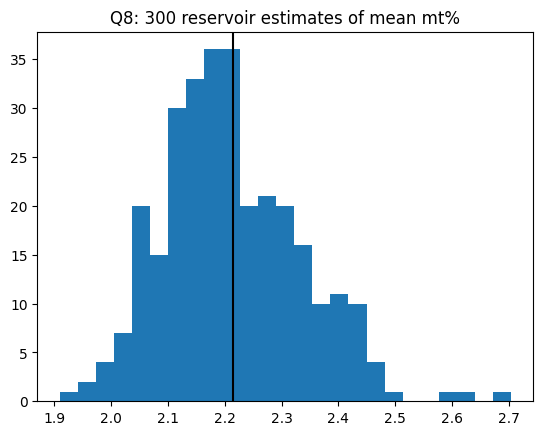

In [15]:
# ---- EXPERIMENT (given): (a) FPR vs memory on (cell, gene) tokens; (b) is the reservoir uniform? ----
cells_A = np.where(leiden == cl_big)[0]; cells_B = np.where(leiden == cl2)[0]
tok = lambda cells: {f"{c}:{g}" for c in cells for g in np.flatnonzero(DET[c])}
inserted = sorted(tok(cells_A))[:20_000]; queries = sorted(tok(cells_B) - set(inserted))[:20_000]
rows = []
for m in [50_000, 200_000, 800_000]:
    for k in [1, 3, 7]:
        bf = Bloom(m, k); [bf.add(x) for x in inserted]
        fpr = np.mean([bf.maybe_contains(x) for x in queries])
        rows.append({"m bits": m, "k": k, "bits/item": round(m / len(inserted), 1), "measured FPR": round(float(fpr), 4),
                     "theory": round((1 - math.exp(-k * len(inserted) / m)) ** k, 4)})
print(pd.DataFrame(rows).to_string(index=False))
print("exact set stores", sum(len(x.encode()) for x in inserted), "bytes of strings (plus hash-table overhead); Bloom(m=200000) stores", Bloom(200_000, 3).nbytes(), "bytes")

# (b) uniformity: inclusion frequency of every cell over 300 reservoirs, and the sample-mean of pct_counts_mt
n_cells = adata_hvg.n_obs; incl = np.zeros(n_cells); est = []
mt = adata_hvg.obs["pct_counts_mt"].values
for t in range(300):
    Rt = reservoir_sample(range(n_cells), 100, seed=t); incl[Rt] += 1; est.append(mt[Rt].mean())
print(f"inclusion frequency: mean {incl.mean()/300:.4f} (target s/n = {100/n_cells:.4f}), min {incl.min()/300:.4f}, max {incl.max()/300:.4f}")
print(f"mean pct_counts_mt: full data {mt.mean():.3f} | reservoir estimates mean {np.mean(est):.3f}, sd {np.std(est):.3f}")
plt.hist(est, bins=25); plt.axvline(mt.mean(), color="k"); plt.title("Q8: 300 reservoir estimates of mean mt%"); plt.show()

**1.	Report measured vs theoretical FPR for the nine (m, k) settings. For fixed m, why does increasing k first lower and then raise the FPR? State the two error types a Bloom filter can and cannot make, and why that asymmetry makes it suitable for the duplicate-screening task of Project 1, Q4.**



**2.	Using the inclusion frequencies and the spread of the 300 mt% estimates, argue that Algorithm R yields a uniform sample without knowing n in advance. Why does the replacement probability have to be exactly s/t at step t, and what would go wrong with a fixed probability?**

---
## Question 9 (10 pts):

In [ ]:
class DGIM:
    """Buckets = list of (end_timestamp, size) with size a power of two, newest last; at most 2 buckets per size."""
    def __init__(self): self.t = 0; self.buckets = []
    def add(self, bit):
        self.t += 1
        if bit != 1: return
        # TODO(1): append (t, 1); then while three buckets share a size, merge the two OLDEST of that size into one of double size (keep the newer end timestamp)
        self.buckets.append((self.t, 1))
        while True:
            sizes = [size for _, size in self.buckets]
            size_counts = collections.Counter(sizes)
            merge_size = next((size for size, count in size_counts.items() if count > 2), None)
            if merge_size is None:
                break
            # Find the indices of the two oldest buckets with the merge_size
            indices_to_merge = [i for i, (_, size) in enumerate(self.buckets) if size == merge_size][:2]
            if len(indices_to_merge) < 2:
                break
            # Merge the two oldest buckets
            idx1, idx2 = indices_to_merge
            new_end_timestamp = self.buckets[idx2][0]  # Keep the newer end timestamp
            new_size = merge_size * 2
            # Remove the two old buckets and add the new merged bucket
            self.buckets.pop(max(idx1, idx2))  # Remove the one with the higher index first
            self.buckets.pop(min(idx1, idx2))
            self.buckets.append((new_end_timestamp, new_size))

    def query(self, N): SOMETHING WRONG HERE
        """Estimated number of 1s among the last N bits: all buckets with end_timestamp > t - N count fully EXCEPT the oldest one, which counts half."""
        # TODO(2)
        count = 0
        threshold_time = self.t - N
        oldest_bucket_size = None
        for end_timestamp, size in reversed(self.buckets):
            if end_timestamp > threshold_time:
                count += size
                oldest_bucket_size = size  # Keep track of the oldest bucket that counts fully
            else:
                break
        if oldest_bucket_size is not None:
            count -= oldest_bucket_size // 2  # Subtract half of the oldest bucket that counts fully
        print(count)
        return count
        raise NotImplementedError

def drift_detector(x, n_ref=300, n_cur=300, delta=0.05, warmup=600):
    """Two-window test on a 0/1 (or bounded) sequence x. Reference = x[warmup-n_ref-n_cur : warmup-n_cur] (fixed);
    current = last n_cur values. Flag the first t >= warmup where |mean_ref - mean_cur| > eps_cut,
    eps_cut = sqrt( ln(4/delta) / (2 m) ), m = 1/(1/n_ref + 1/n_cur). Return that t or None."""
    # TODO(3)
    raise NotImplementedError

# ---- asserts on the handout bit stream + a synthetic check of the 50% bound ----
d = DGIM(); [d.add(b) for b in [1, 1, 0, 1, 1, 1, 0, 1, 1, 1]]
assert d.query(6) == 6, f"Q9 assert FAILED - handout example should estimate 6, got {d.query(6)}"
rng = np.random.RandomState(5); bits = (rng.rand(5000) < 0.3).astype(int); d = DGIM(); worst = 0
for i, b in enumerate(bits):
    d.add(b)
    if i >= 1000 and i % 97 == 0:
        exact = bits[i - 999:i + 1].sum(); worst = max(worst, abs(d.query(1000) - exact) / exact)
assert worst <= 0.5, f"Q9 assert FAILED - DGIM relative error {worst:.2f} exceeds 50%"
assert drift_detector(np.r_[np.zeros(1000), np.ones(1000)]) is not None and drift_detector(np.zeros(2000)) is None, "Q9 assert FAILED - detector"
print(f"Q9 asserts PASSED | worst DGIM relative error over the synthetic stream: {worst:.3f}")

7
7


AssertionError: Q9 assert FAILED - handout example should estimate 6, got 7

In [ ]:
# ---- EXPERIMENT (given): a cell stream that changes regime; count a marker in a window; detect the drift ----
# regime 1: 900 cells from the largest cluster; regime 2: a 50/50 mix of the two largest clusters
rng = np.random.RandomState(11)
seg1 = rng.permutation(cells_A)[:900]
nB = min(300, len(cells_B)); seg2 = rng.permutation(np.concatenate([rng.choice(cells_A, nB, replace=False), rng.choice(cells_B, nB, replace=False)]))
order = np.concatenate([seg1, seg2]); CHANGE = len(seg1)
# marker: the HVG whose detection rate differs most between the two clusters
diff = DET[cells_B].mean(0) - DET[cells_A].mean(0); g_star = int(np.argmax(diff)); G = adata_hvg.var_names[g_star]
bits = DET[order, g_star].astype(int)
print(f"marker {G}: detection {DET[cells_A, g_star].mean():.2f} in cluster {cl_big} vs {DET[cells_B, g_star].mean():.2f} in cluster {cl2}; change point at t={CHANGE}")

d = DGIM(); est, exact, ts = [], [], []
for i, b in enumerate(bits):
    d.add(b)
    if i >= 300 and i % 25 == 0:
        ts.append(i); est.append(d.query(300)); exact.append(bits[i - 299:i + 1].sum())
plt.plot(ts, exact, "k-", label="exact count in last 300"); plt.plot(ts, est, "o--", ms=3, label="DGIM estimate"); plt.axvline(CHANGE, color="r", ls=":")
plt.xlabel("t (cells seen)"); plt.ylabel(f"# cells expressing {G}"); plt.legend(); plt.title("Q9: a window statistic on a stream"); plt.show()
print("max |DGIM - exact| / exact:", round(float(np.max(np.abs(np.array(est) - np.array(exact)) / np.maximum(np.array(exact), 1))), 3), "| buckets stored at the end:", len(d.buckets))

t_det = drift_detector(bits, n_ref=300, n_cur=300, delta=0.05, warmup=600)
print(f"drift flagged at t = {t_det} (true change at {CHANGE}; delay = {None if t_det is None else t_det - CHANGE})")
pre = [drift_detector(bits[:CHANGE], n_ref=300, n_cur=300, delta=0.05, warmup=600)]
print("false alarm before the change point?", pre[0] is not None)

**1.	Report the worst DGIM relative error and the number of buckets stored versus the 300 bits an exact sliding window would keep. Explain where the error comes from (which bucket, and why half) and why the memory is logarithmic in the window length.**



**2.	Report the detection time and delay. Which two quantities set the detector's sensitivity, and how would a smaller δ or a smaller n_cur trade false alarms against delay? Connect this to Week 6: on a stream, what does "normal according to whom" gain as a second question?**

---
## Question 10 (10 pts):

**Comment 1:** *"Frequent is not interesting."* — "The authors report dozens of frequent gene sets, but any pair of broadly expressed genes is frequent. Nothing here distinguishes co-regulation from co-abundance." Respond with evidence from Q3 (confidence vs lift, Simpson) and Q5 (swap-randomized null, multiple comparisons): which of your frequent pairs survive, and what exactly did each test rule out?

**Comment 2:** *"Why approximate?"* — "The dataset has 2,700 cells. Sketches, Bloom filters and reservoirs are unnecessary; just count." Respond using Q7, Q8 and Q9: for each structure, state the exact-counting cost it replaces, the error guarantee you measured, and one regime (data size or arrival pattern) where the reviewer is right and one where they are wrong.

**Comment 3:** *"Convince me."* — "What single additional analysis would most strengthen the paper?" Propose one experiment in 3–5 sentences: what you would run, what result you predict, and what result would instead make you change the pipeline. An experiment that cannot fail is not an experiment.